# Quadro de afirmações: o que os números sustentam

Este caderno reúne, num quadro só, as conclusões dos cadernos `incerteza` e `robustez_mistura`. Cada linha é uma **afirmação** escrita
antes de olhar o resultado (a lista é fixa, são 9) e recebe um **veredito**.

**Como se decide.** Compara-se o **último período (1871–1888)** com uma **base**: o primeiro período em que há pelo menos 30 anúncios
(e, nas visões ajustadas, 30 anúncios *efetivos*). A base é escolhida por visão; se a da visão bruta e a da visão só JC forem diferentes, o quadro mostra as duas.

| Visão | O que é |
|---|---|
| **Bruta** | todos os anúncios do corpus |
| **Só JC** | só o Jornal do Commercio (sem os bibs `094170_01` e `706744`) |
| **Ajustada** | só para as afirmações 7 a 9: a mistura de tipos (fuga, aluguel, venda, ama de leite) é igualada entre os períodos |

| Veredito | Quer dizer |
|---|---|
| **sustentada** | a tendência bruta passa no teste (p ajustado < 0,05), a diferença último − base tem intervalo de 95% sem zero na bruta e na só JC (e, nos temas, na ajustada), sempre no sentido da frase |
| **parcial** | o sentido é o da frase em todas as visões, mas o intervalo contém zero em alguma (ou o teste de tendência não passa) |
| **não sustentada** | o sentido muda entre as visões, ou contraria a frase, ou o intervalo da visão bruta contém zero, ou a visão ajustada de um tema não confirma |
| **frágil** | mesmo na base alternativa, a base ou o último período têm menos de 30 anúncios em alguma visão |

**Forma.** *Um degrau* = mais de 60% da mudança total acontece num só passo entre períodos vizinhos; senão, *gradual*.

> **As afirmações 6 a 9 não são achados históricos.** A 6 mede a **mistura da amostra** (quantos anúncios de fuga a busca achou); as 7 a 9 são **temas, que acompanham o tipo do anúncio**.
> Por isso um veredito "sustentada" nelas leva o aviso "(ver natureza)": descreve a amostra, não o que mudou na escravidão.

Corpus `corp3`, campos `c6`, temas `t5`. Os números dos comentários foram lidos da saída
da própria execução; se o banco mudar, **confira os números de novo**.

> **Cuidado ao ler:** (1) os anúncios vêm de **frases de busca**, não de sorteio; (2) **o bootstrap usa o modelo de temas fixo** e não mede a
> instabilidade do LDA; (3) os anúncios de um período não são independentes (reanúncios, mesmo dono), então **os intervalos são um pouco otimistas**;
> (4) "não sustentada" não prova que nada mudou: pode faltar anúncio.

## Preparação: ler o corpus e calcular as medidas

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from hdb import config
from hdb.afirmacoes import AFIRMACOES, formatar, quadro
from hdb.banco import BancoSupabase
from hdb.medidas import MIN_N, PERIODOS, calcular, carregar

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
df = carregar(BancoSupabase(), config)
print(f"{len(df)} anúncios no corpus {config.VERSAO_CORPUS} com período legal")
if len(df) != 2191:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 2191 anúncios e agora são {len(df)}: "
          "confira os números dos textos antes de usar.")
RESULTADOS = calcular(df)
QUADRO = quadro(RESULTADOS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2191 anúncios no corpus corp3 com período legal


## 1. O quadro
Valores em % (idade em anos). A diferença é último − base, com intervalo de 95% por bootstrap (2.000 repetições, semente fixa).

In [2]:
display(Markdown(formatar(QUADRO)))

| # | Afirmação | Natureza | Base | Valor base → último (bruta) | Valor base → último (só JC) | Diferença [IC 95%] (bruta / só JC / ajustada) | p aj. | Forma | Veredito | Motivo |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | A recompensa nas fugas diminui | dentro do tipo | bruta: antes de 1831; só JC: 1831–1850 | 66,2 → 25,8 | 65,7 → 25,8 | -40,4 [-55,0; -25,6] / -39,9 [-53,2; -27,4] | <0,001 | gradual | **sustentada** | Tendência bruta com p ajustado < 0,05 e diferença com intervalo sem zero, no mesmo sentido, em todas as visões. |
| 2 | A nação citada nas fugas diminui | dentro do tipo | bruta: antes de 1831; só JC: 1831–1850 | 63,2 → 0,0 | 50,0 → 0,0 | -63,2 [-75,0; -51,5] / -50,0 [-59,3; -40,7] | <0,001 | gradual | **sustentada** | Tendência bruta com p ajustado < 0,05 e diferença com intervalo sem zero, no mesmo sentido, em todas as visões. |
| 3 | As marcas no corpo nas fugas diminuem | dentro do tipo | bruta: antes de 1831; só JC: 1831–1850 | 48,5 → 17,2 | 21,3 → 17,2 | -31,3 [-45,6; -16,8] / -4,1 [-15,0; 6,8] | <0,001 | um degrau | **parcial** | Mesmo sinal em todas as visões, mas o intervalo da diferença contém zero na visão só JC. |
| 4 | A idade mediana dos fugidos aumenta | dentro do tipo | 1831–1850 | 20,8 → 29,0 | 20,8 → 29,0 | 8,2 [1,5; 14,0] / 8,2 [1,5; 14,0] anos | <0,001 | gradual | **frágil** | Na visão bruta o último período tem menos de 30 anúncios (n ou n efetivo). |
| 5 | A parcela feminina dos aluguéis aumenta | dentro do tipo | 1831–1850 | 55,8 → 68,9 | 55,6 → 68,9 | 13,1 [2,8; 23,3] / 13,4 [2,4; 23,8] | 0,016 | gradual | **sustentada** | Tendência bruta com p ajustado < 0,05 e diferença com intervalo sem zero, no mesmo sentido, em todas as visões. |
| 6 | A fuga perde peso entre os anúncios | mistura da amostra | antes de 1831 | 44,7 → 23,9 | 28,8 → 23,9 | -20,8 [-29,9; -11,8] / -4,9 [-17,5; 7,6] | <0,001 | um degrau | **parcial** | Mesmo sinal em todas as visões, mas o intervalo da diferença contém zero na visão só JC. |
| 7 | Os temas de fuga perdem peso | tema (acompanha o tipo) | antes de 1831 | 46,3 → 25,2 | 31,7 → 25,2 | -21,1 [-28,9; -13,5] / -6,5 [-17,3; 4,4] / -2,6 [-10,3; 3,8] | 0,877 | um degrau | **não sustentada** | Igualando a mistura de tipos, o intervalo da diferença contém zero: a tendência bruta do tema é, em boa parte, mistura de tipos. |
| 8 | O serviço doméstico ganha peso | tema (acompanha o tipo) | antes de 1831 | 28,0 → 42,8 | 35,5 → 42,8 | 14,8 [8,4; 21,4] / 7,3 [-2,8; 17,0] / -6,4 [-15,1; 3,6] | <0,001 | um degrau | **não sustentada** | O sinal da diferença muda ou some na visão ajustada. |
| 9 | A ama de leite perde peso | tema (acompanha o tipo) | antes de 1831 | 17,4 → 11,2 | 22,4 → 11,2 | -6,1 [-11,1; -1,4] / -11,2 [-20,0; -2,7] / -3,2 [-8,2; 1,7] | <0,001 | gradual | **não sustentada** | Igualando a mistura de tipos, o intervalo da diferença contém zero: a tendência bruta do tema é, em boa parte, mistura de tipos. |

**O que o quadro diz, afirmação por afirmação:**

- **Sustentadas (3):** a **recompensa** nas fugas diminui (66,2% para 25,8%; só com o JC, de 65,7% para 25,8%), a **nação citada** nas fugas diminui (63,2% para 0,0%; só com o JC, de 50,0% para 0,0%) e a **parcela feminina dos aluguéis** aumenta (55,8% para 68,9%, base 1831–1850). Nas três, o intervalo da diferença não inclui zero na visão bruta nem só com o JC, o sentido é o mesmo e o p ajustado é menor que 0,05.
- **Parcial (2):** as **marcas no corpo** nas fugas diminuem (48,5% para 17,2%), mas **só com o JC** a diferença é de −4,1 pontos com intervalo de −15,0 a 6,8: a queda estava quase toda no primeiro período, que tem muito Diário do Rio. E a **fuga entre os anúncios** (44,7% para 23,9%) fica em −4,9 só com o JC (intervalo −17,5 a 7,6): **a queda era em boa parte o Diário do Rio no primeiro período**.
- **Frágil (1):** a **idade mediana dos fugidos** sobe de 20,8 para 29,0 anos (base 1831–1850) e o intervalo da diferença vai de 1,5 a 14,0, mas o último período tem só 26 fugas com idade (menos de 30), e a fração de fugas que citam idade também muda de 23% a 51%.
- **Não sustentadas (3, todas de temas):** a queda da parcela dos **temas de fuga**, a alta do **serviço doméstico** e a queda da **ama de leite** desaparecem quando se iguala a mistura de tipos. No serviço doméstico o sinal até **inverte** (+14,8 na bruta, −6,4 na ajustada, intervalo −15,1 a 3,6).

**Forma:** das 9 afirmações, 4 são "um degrau" (a maior parte da mudança está em um só passo entre períodos vizinhos: marcas, fuga entre os anúncios e os temas de fuga e de serviço doméstico) e 5 são graduais: recompensa, nação citada, idade, parcela feminina dos aluguéis e ama de leite. A recompensa, por exemplo, vai de 65,7% (1831–1850) a 47,2% e 25,8%, passo a passo.

## 2. Gráficos: valor por período, uma linha por visão
**Círculo aberto** = n (ou n efetivo) menor que 30 naquele período e visão. Cada gráfico traz o veredito.

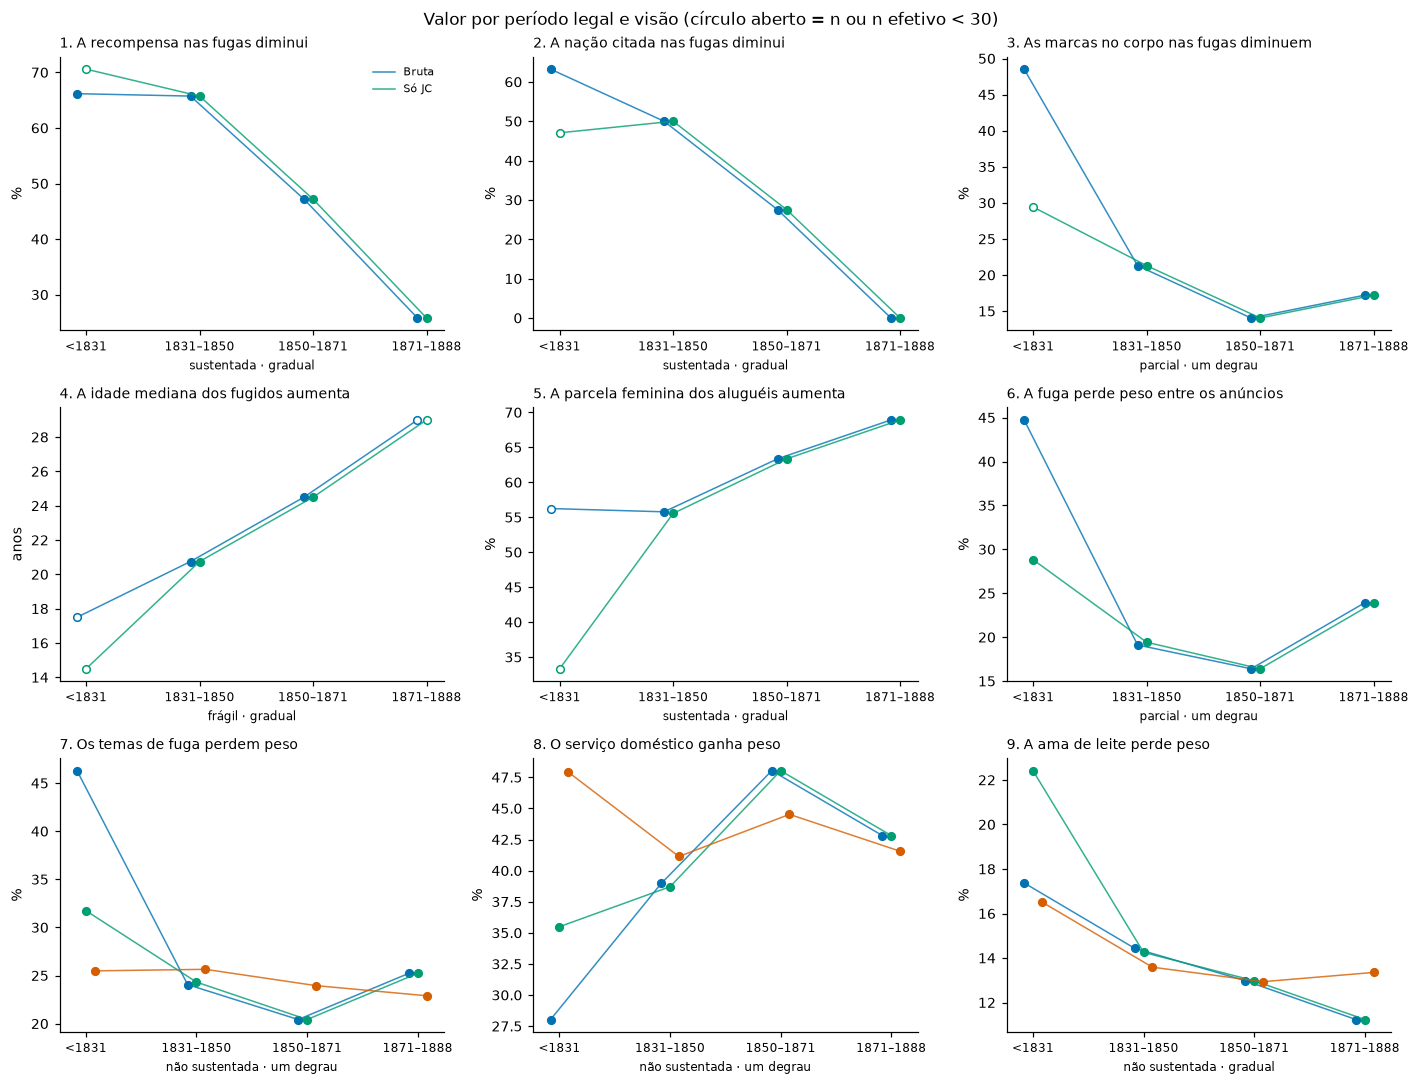

In [3]:
CORES = {"bruta": "#0072B2", "jc": "#009E73", "ajustada": "#D55E00"}
ROTULO = {"bruta": "Bruta", "jc": "Só JC", "ajustada": "Ajustada"}
fig, eixos = plt.subplots(3, 3, figsize=(13, 10))
for ax, l in zip(eixos.ravel(), QUADRO):
    r = RESULTADOS[l["id"]]
    ax.set_title(f"{l['id']}. {l['texto']}", fontsize=9, loc="left")
    for k, v in enumerate(["bruta", "jc", "ajustada"]):
        if v not in r:
            continue
        xs = [i + (k - 1) * 0.08 for i, p in enumerate(PERIODOS) if r[v][p]["n"] > 0]
        ys = [r[v][p]["valor"] for p in PERIODOS if r[v][p]["n"] > 0]
        ax.plot(xs, ys, color=CORES[v], lw=1, alpha=0.8, label=ROTULO[v])
        for i, p in enumerate(PERIODOS):
            c = r[v][p]
            if c["n"] > 0:
                ax.plot(i + (k - 1) * 0.08, c["valor"], "o", color=CORES[v], ms=5,
                        mfc="white" if min(c["n"], c["n_ef"]) < MIN_N else CORES[v])
    ax.set_xticks(range(len(PERIODOS)))
    ax.set_xticklabels([p.replace("antes de ", "<") for p in PERIODOS], fontsize=8)
    ax.set_ylabel("anos" if l["id"] == 4 else "%")
    ax.set_xlabel(l["veredito"] + f" · {l['forma']}", fontsize=8)
eixos[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("Valor por período legal e visão (círculo aberto = n ou n efetivo < 30)")
fig.tight_layout(); plt.show()

**Como ler os gráficos:** cada linha é uma visão (bruta, só JC e, nos temas, ajustada). Círculo aberto indica menos de 30 anúncios (ou n efetivo menor que 30). Quando as linhas das visões se separam, a conclusão depende da visão. Isso é o que acontece nos três temas: a linha bruta cai ou sobe, e a ajustada fica plana.

## 3. O que fica de pé

**O que o quadro autoriza dizer:**

1. Nas fugas, a **recompensa** e, sobretudo, a **nação citada** diminuem ao longo do tempo, e isso resiste ao ajuste de jornal. A recompensa é estável até 1850 (66,2% e 65,7%) e cai depois, em dois passos (47,2% e 25,8%); a nação cai em todos os passos.
2. Nos aluguéis, a **parcela feminina cresce** (55,8% para 68,9% do período 1831–1850 ao de 1871–1888).
3. **Os temas do LDA não autorizam falar em mudança de conteúdo ao longo do tempo**: eles acompanham o tipo do anúncio, e a variação entre períodos é mistura de tipos.

**O que o quadro NÃO autoriza dizer:** que a fuga "diminui" (é efeito de o primeiro período incluir o Diário do Rio) nem que o serviço doméstico "cresce"; nem usar a idade dos fugidos como tendência (n pequeno). Nada aqui diz respeito a **1888**, que continua sem páginas no acervo que temos.

**Nota sobre o critério:** o critério de veredito foi escrito antes de ver o resultado. Uma frase dele, para os temas ("a ajustada tem intervalo com zero e a direção bruta não se repete nela"), foi lida pelo agente de forma literal e deu "parcial" para dois temas. **Eu a esclareci depois de ver o resultado**: se a tendência de um tema some ao igualar a mistura, ela é mistura de tipos e o veredito é "não sustentada". Com a leitura literal, os temas de fuga e de ama de leite seriam "parcial"; a conclusão sobre o serviço doméstico (sinal oposto) não muda.

**Validação dos campos (caderno `validacao_campos`):** o código perde parte das recompensas (acha 77% das que existem num conjunto de teste novo) e a validação mostrou que, nas amostras pequenas, a queda dele era exagerada. A verdade rotulada por Claude, juntando 35 fugas por período, **confirma as três afirmações de campos**: recompensa de 80% para 40% (p = 0,001), nação citada de 63% para 0% (p < 0,001) e marcas no corpo de 66% para 20% (p < 0,001). Por isso a afirmação 1 fica **sustentada**, mas **o nível do código (66% a 26%) é menor que o real**, e vale como tendência. A idade mediana (afirmação 4) segue frágil: o último período tem 26 fugas com idade e a própria fração de fugas que citam idade sobe (23% para 51%). Os rótulos são de Claude, não do grupo.